
<div align="center">

<img src="https://capsule-render.vercel.app/api?type=waving&color=0:050B18,50:0B3D91,100:123B60&height=190&section=header&text=Luis%20Barahona&fontSize=42&fontColor=FFFFFF&fontAlignY=38&desc=DATA%20ENGINEERING%20%7C%20ARTIFICIAL%20INTELLIGENCE%20%7C%20DEVELOPER&descAlignY=62&descSize=14" width="50%" alt="Luis Barahona MX- Data Engineering and AI">

<img src="https://readme-typing-svg.demolab.com?font=Fira+Code&weight=500&size=17&duration=3500&pause=1200&color=38BDF8&center=true&vCenter=true&width=600&lines=Python+%7C+SQL+%7C+Data+Engineering;Artificial+Intelligence+%7C+Machine+Learning;Data+Science+%7C+Cloud+Computing;Building+Technology+for+the+Future" alt="Technical expertise">

</div>

---
<div align="center">
### Professional Profile

I am a Mexican Data Engineer and a 2026 graduate of Universidad del Caribe, passionate about technology, innovation, and continuous learning.
Beyond technical expertise, I value communication, teamwork, collaboration, and building meaningful connections with others. I believe that every person offers an opportunity to learn something new, and I am always motivated to share knowledge, explore new ideas, and grow both personally and professionally.

---

<div align="center">

<img src="https://skillicons.dev/icons?i=python,mysql,postgres,git,github,react,firebase,linux,docker,vscode&theme=dark" alt="Technical skills">


<strong>Data Engineering ·  Data Analytics · Data science · Artificial Intelligence · Machine Learning · Data Analytics · Developer</strong>

</div>

---
<div align="center">

| Platform | Contact |
|:---|:---|
| Email | [190300395@ucaribe.edu.mx](mailto:190300395@ucaribe.edu.mx) |
| GitHub | [github.com/LuisBarahonaMX](https://github.com/LuisBarahonaMX) |
| LinkedIn | [linkedin.com/in/luis-barahona-mx](https://www.linkedin.com/in/luis-barahona-mx/) |
| Instagram | [@luisbarahonamx](https://www.instagram.com/luisbarahonamx/) |
| X | [@luisbarahonaMX](https://x.com/luisbarahonaMX) |
| Website | [SIKO AI Platform](https://sikoai.web.app/) |
</div>



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

# Análisis de componentes principales

Una opción para reducir la dimensionalidad de un conjunto de datos es el **análisis de componentes principales**. Esta técnica se emplea con mucho éxito para comprimir imágenes, audio, o series de tiempo.

En esta sección revisaremos los principios que sustentan a esta técnica y sus aplicaciones en diferentes contextos.

Para explorar la técnica, considera el siguiente conjunto de datos compuesto por dos variables:

In [ ]:
n = 100

np.random.seed(123)
x = 5*(2*np.random.uniform(size=n)-1)
y = x+np.random.normal(size=n)

X = np.column_stack((x,y))
df = pd.DataFrame({"x1": X[:,0], "x2": X[:,1]})
df.to_csv("datos_pca.csv")
df.head()

,x1,x2
0,1.964692,4.051805
1,-2.138607,-1.974165
2,-2.731485,-1.581280
3,0.513148,-0.754204
4,2.194690,2.375725


Los datos pueden visualizarse en la siguiente gráfica de dispersión:

In [ ]:
import os
print(os.getcwd())  # Muestra el directorio de trabajo actual
print(os.listdir())  # Lista los archivos en el directorio


/content
['.config', 'datos_pca.csv', 'sample_data']


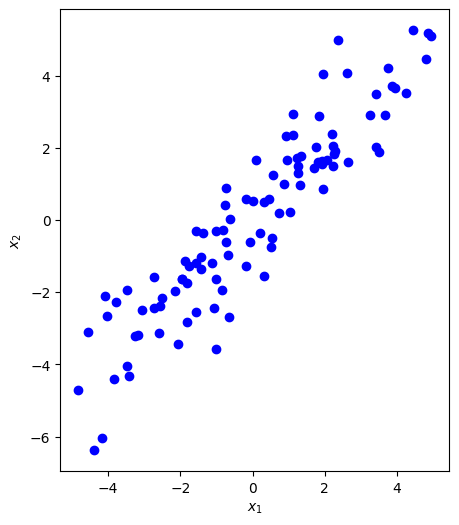

In [ ]:
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111)
plt.plot(x,y,'bo')
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
ax.set_aspect('equal')
plt.show()

## Dimensionalidad

Las variables originales, $x_1$ y $x_2$ definen dos ejes perpendiculares y para **ubicar una observación** en el espacio requerimos **dos números**; el primero de ellos indica cuánto debemos movernos en la dirección del eje $x_1$ y el segundo cuánto debemos movernos en la dirección del eje $x_2$.

Por ejemplo, ubicamos la primera observación:


In [ ]:
X[0,]

array([1.96469186, 4.05180522])

identificando que debemos trasladarnos $1.96$ unidades en la dirección de $x_1$ y posteriormente $4.05$ unidades en la dirección $x_2$.

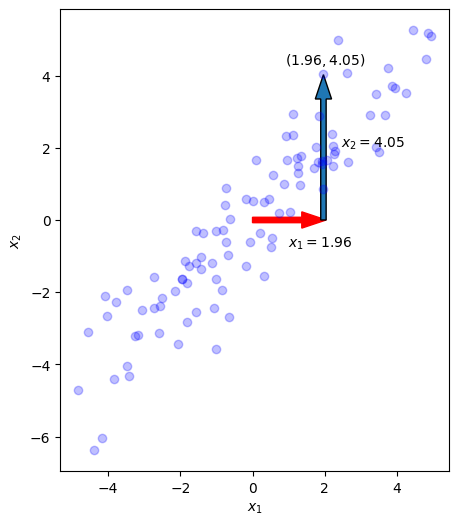

In [ ]:
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111)

plt.plot(x,y,'bo', alpha=0.25)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.arrow(0, 0, X[0,0]-0.6, 0, width=0.15, color="r")
plt.arrow(X[0,0], 0, 0, X[0,1]-0.7, width=0.15)
plt.annotate("$x_1 = 1.96$", xy=(X[0,0]/2, -0.75))
plt.annotate("$x_2 = 4.05$", xy=(X[0,0]+0.5, X[0,1]/2))
plt.annotate("$(1.96, 4.05)$", xy=(0.9, 4.3))
ax.set_aspect('equal')
plt.show()

## Elección de los ejes

La elección de los ejes que se usan como referencia para ubicar a las observaciones es un tanto arbitraria. Podemos elegir **otros ejes** que simplifiquen la ubicación de cualquier punto (dadas las características de la distribución de los datos). En la siguiente gráfica se muestra una opción:  

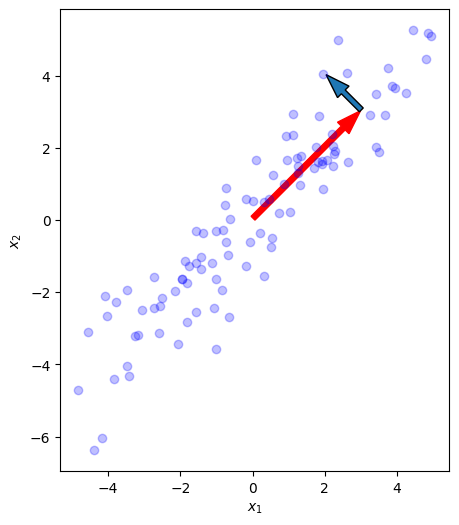

In [ ]:
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111)

xm = np.mean(X, axis = 0)

plt.plot(x,y,'bo', alpha = 0.25)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
d = 2.5
plt.arrow(xm[0], xm[1], d, d, width=0.15, color="r")
plt.arrow(xm[0]+d+0.5, xm[1]+d+0.5, -d/5, d/5, width=0.15)
ax.set_aspect('equal')
plt.show()

**Nuevas coordenadas**

Aunque ahora para llegar al punto es necesario caminar $6.02$ unidades sobre el eje rojo y $2.09$ unidades sobre el eje azul.


In [ ]:
print(X[0,0]+X[0,1])
print(-X[0,0]+X[0,1])


6.016497071545418
2.0871133595881854



Como aclaración, los nuevos ejes pueden obtenerse con una transformación lineal de los originales:

\begin{align}
  x_1' &= x_1+x_2\\
  x_2' &= -x_1+x_2\\
\end{align}


**¿Qué ventaja se tiene al utilizar los nuevos ejes coordenados?**

* Si debieras elegir un solo eje para desplazarte entre los puntos de la gráfica de dispersión, ¿cuál elegirías?, ¿el horizontal?, ¿vertical?, ¿alguno de los inclinados?


Reducir la dimensionalidad de este conjunto de datos, equivale a **limitarnos a usar un solo eje**. Observa que en el caso de los ejes originales, difícilmente quedaríamos cerca de las observaciones si podemos movernos solamente sobre un eje:



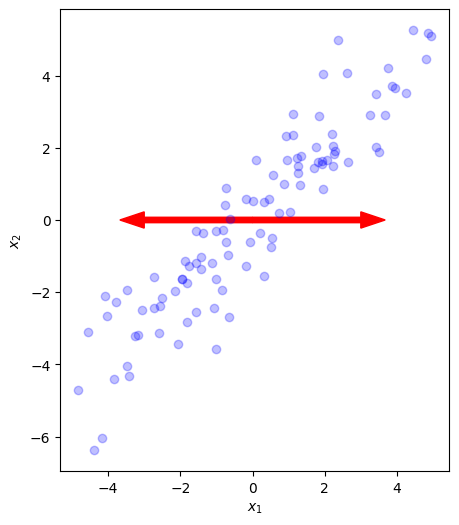

In [ ]:
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111)

plt.plot(x,y,'bo', alpha=0.25)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.arrow(0, 0, 3, 0, width=0.15, color="r")
plt.arrow(0, 0, -3, 0, width=0.15, color="r")
ax.set_aspect('equal')
plt.show()

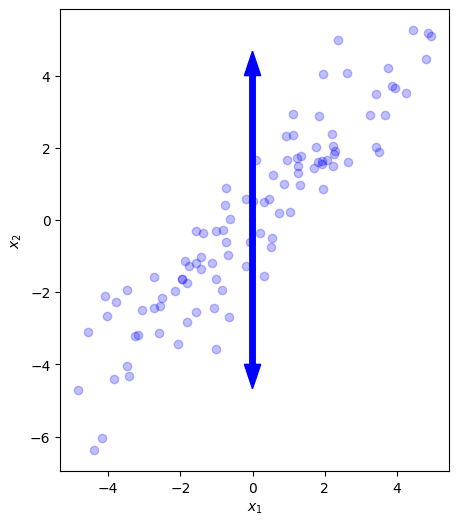

In [ ]:
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111)

plt.plot(x,y,'bo', alpha=0.25)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.arrow(0, 0, 0, 4, width=0.15, color="b")
plt.arrow(0, 0, 0, -4, width=0.15, color="b")
ax.set_aspect('equal')
plt.show()

En el caso de los ejes inclinados, es posible utilizar el eje rojo para *acercarse más* a la mayoría de los puntos:

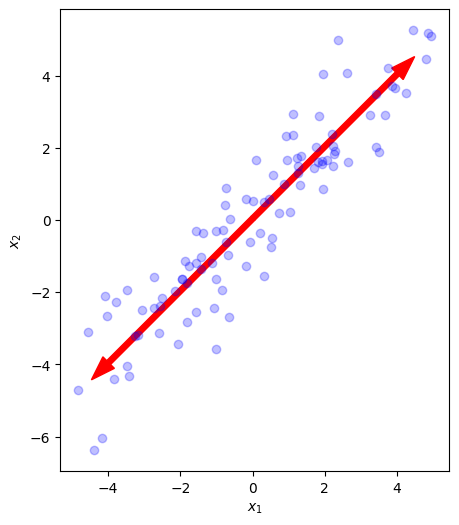

In [ ]:
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111)

xm = np.mean(X, axis = 0)

plt.plot(x,y,'bo', alpha = 0.25)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
d = 4
plt.arrow(xm[0], xm[1], d, d, width=0.15, color="r")
plt.arrow(xm[0], xm[1], -d, -d, width=0.15, color="r")
ax.set_aspect('equal')
plt.show()

##**Para definir este eje hemos identificado la dirección en la que los datos tienen una mayor variabilidad.**

Las observaciones, por cierto, pueden **aproximarse** muy bien si se $\texttt{proyectan}$ sobre dicho eje:

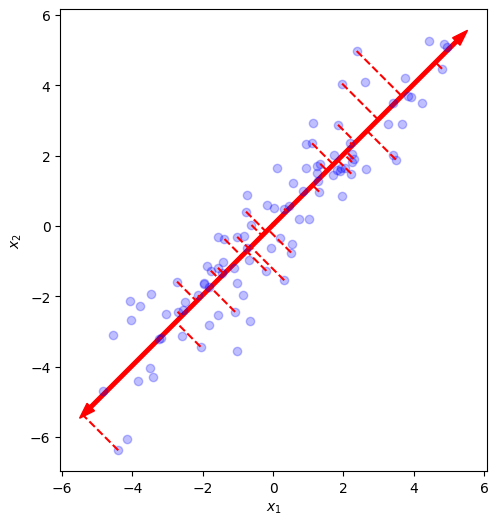

In [ ]:
T_inv = np.matrix([[1,-1],[1,1]])
T = np.linalg.inv(T_inv)
Xt = X-xm
Xp = np.transpose(np.dot(T, np.transpose(Xt)))

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111)
plt.plot(x,y,'bo', alpha = 0.25)

#proyecta algunas observaciones
for i in range(30):
  xip = xm+Xp[i,0]*np.array([1,1])
  plt.plot([X[i,0],xip[0]], [X[i,1],xip[1]], "r--")

plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
d = 5.2
plt.arrow(xm[0], xm[1], d, d, width=0.1, color="r")
plt.arrow(xm[0], xm[1], -d, -d, width=0.1, color="r")
ax.set_aspect('equal')
plt.show()

Para este ejemplo, definimos nuevos ejes coordenados mediante **transformaciones lineales** de los ejes originales, $x_1$ y $x_2$:

\begin{align}
  x_1' &= x_1+x_2\\
  x_2' &= -x_1+x_2
\end{align}

##<font color="red">¿Cómo podemos obtener nuevos ejes alineados hacia donde los datos presentan la mayor variabilidad?</font>





## Análisis de componentes principales

La idea del **análisis de componentes principales** es la de construir nuevas variables (nuevos ejes coordenados) a partir de una transformación lineal de las originales.

* Una **transformación lineal** genera nuevos ejes para ubicar a los datos originales.

Vamos a imponer algunas condiciones a la transformación lineal.



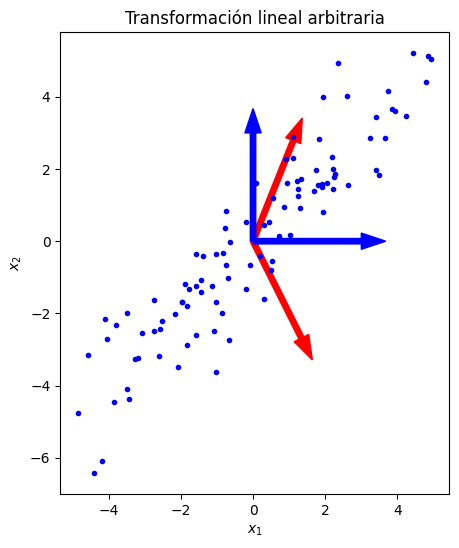

In [ ]:
#variables originales
x1 = np.array([1,0])
x2 = np.array([0,1])

#variables transformadas (ejemplos arbitrarios)
x1t = x1-2*x2
x1t = x1t/np.linalg.norm(x1t)

x2t = 2*x1+5*x2
x2t = x2t/np.linalg.norm(x2t)

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111)

plt.plot(Xt[:,0],Xt[:,1],'b.')
plt.arrow(0,0,3*x1t[0],3*x1t[1], width=0.15, color="r")
plt.arrow(0,0,3*x2t[0],3*x2t[1], width=0.15, color="r")

plt.arrow(0,0,3*x1[0],3*x1[1], width=0.15, color="b")
plt.arrow(0,0,3*x2[0],3*x2[1], width=0.15, color="b")

plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Transformación lineal arbitraria")

ax.set_aspect('equal')

plt.show()

# Ortogonalidad

* Exigimos que las nuevas variables sean ortogonales entre sí:

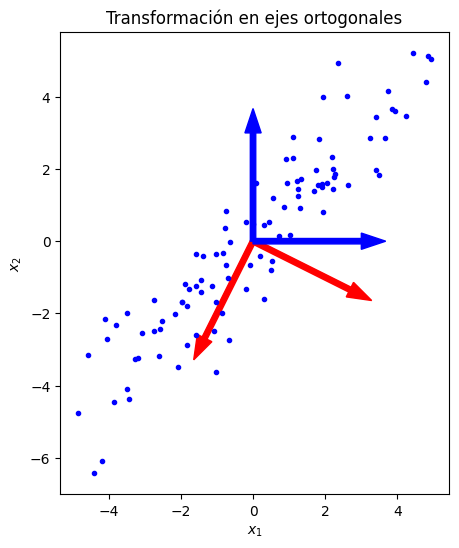

In [ ]:
#variables originales
x1 = np.array([1,0])
x2 = np.array([0,1])

#variables transformadas (ejemplos arbitrarios)
x1t = np.array([2,-1])
x1t = x1t/np.linalg.norm(x1t)

x2t = np.array([x1t[1],-x1t[0]])
x2t = x2t/np.linalg.norm(x2t)

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111)


plt.plot(Xt[:,0],Xt[:,1],'b.')
plt.arrow(0,0,3*x1t[0],3*x1t[1], width=0.15, color="r")
plt.arrow(0,0,3*x2t[0],3*x2t[1], width=0.15, color="r")
plt.arrow(0,0,3*x1[0],3*x1[1], width=0.15, color="b")
plt.arrow(0,0,3*x2[0],3*x2[1], width=0.15, color="b")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Transformación en ejes ortogonales")

ax.set_aspect('equal')

plt.show()


# Maximización de la varianza

* Elegiremos direcciones que maximicen la varianza proyectada sobre ellos:

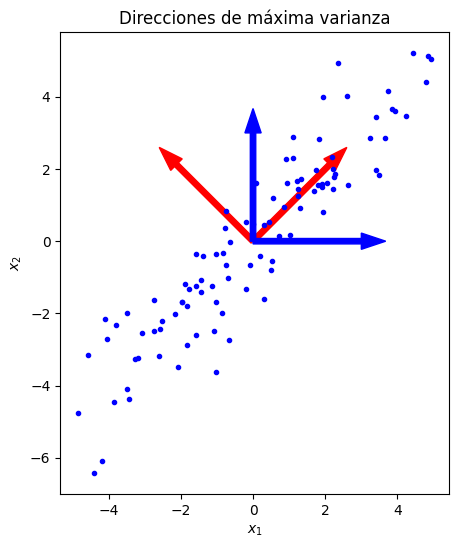

In [ ]:
#variables originales
x1 = np.array([1,0])
x2 = np.array([0,1])

#variables transformadas (ejemplos arbitrarios)
x1t = np.array([1,1])
x1t = x1t/np.linalg.norm(x1t)

x2t = np.array([-x1t[1],x1t[0]])
x2t = x2t/np.linalg.norm(x2t)

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111)
plt.plot(Xt[:,0],Xt[:,1],'b.')
plt.arrow(0,0,3*x1t[0],3*x1t[1], width=0.15, color="r")
plt.arrow(0,0,3*x2t[0],3*x2t[1], width=0.15, color="r")
plt.arrow(0,0,3*x1[0],3*x1[1], width=0.15, color="b")
plt.arrow(0,0,3*x2[0],3*x2[1], width=0.15, color="b")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Direcciones de máxima varianza")
ax.set_aspect('equal')
plt.show()

A los nuevos ejes coordenados se les llama **componentes principales**.



### ¿Qué es la matriz de covarianza?

La matriz de covarianza es una matriz cuadrada que resume la **relación de covarianza** entre las diferentes variables de un conjunto de datos. Se utiliza ampliamente en estadísticas, análisis de datos y, en este caso, en el **Análisis de Componentes Principales (PCA)**.

#### Fórmula general:
$$
C = \frac{(X - \mu_X)^{T}(X - \mu_X)}{N - 1}
$$

Donde:
- \( C \): Matriz de covarianza.
- \( X \): Matriz de datos originales (cada fila representa una observación, y cada columna una variable).
- \( \mu_X \): Vector de medias de cada columna (variable).
- \( N \): Número de observaciones en los datos.



### Componentes clave en la fórmula

1. **Restar la media (\( X - \mu_X \))**:
   Para calcular la covarianza, primero centramos los datos restando la media de cada columna:
   $$
   X - \mu_X
   $$

   Esto asegura que las variables tengan una media de 0, lo cual es crucial para el PCA porque mide variaciones relativas.

2. **Producto matricial**:
   Multiplicamos la transpuesta de la matriz centrada por la matriz centrada original:
   $$
   (X - \mu_X)^{T}(X - \mu_X)
   $$

   Esto calcula las **covarianzas** entre todas las combinaciones de variables:
   - Las diagonales son las **varianzas**.
   - Los valores fuera de la diagonal son las **covarianzas**.

3. **División por \( N-1 \)**:
   Dividir por \( N-1 \) normaliza el cálculo para obtener una estimación insesgada de la covarianza:
   $$
   C = \frac{(X - \mu_X)^{T}(X - \mu_X)}{N - 1}
   $$


### Ejemplo sencillo

Supongamos que tienes un conjunto de datos \( X \) con dos variables (\( x_1, x_2 \)) y tres observaciones:
$$
X =
\begin{bmatrix}
1 & 2 \\
3 & 4 \\
5 & 6
\end{bmatrix}
$$

1. **Calcular las medias (\( \mu_X \))**:
   $$
   \mu_X =
   \begin{bmatrix}
   \text{mean}(x_1) \\
   \text{mean}(x_2)
   \end{bmatrix} =
   \begin{bmatrix}
   3 \\
   4
   \end{bmatrix}
   $$

2. **Centrar los datos (\( X - \mu_X \))**:
   $$
   X - \mu_X =
   \begin{bmatrix}
   1 - 3 & 2 - 4 \\
   3 - 3 & 4 - 4 \\
   5 - 3 & 6 - 4
   \end{bmatrix} =
   \begin{bmatrix}
   -2 & -2 \\
   0 & 0 \\
   2 & 2
   \end{bmatrix}
   $$

3. **Calcular la matriz de covarianza (\( C \))**:
   $$
   C = \frac{(X - \mu_X)^{T}(X - \mu_X)}{N-1}
   $$

   - Producto matricial:
     $$
     (X - \mu_X)^{T}(X - \mu_X) =
     \begin{bmatrix}
     8 & 8 \\
     8 & 8
     \end{bmatrix}
     $$

   - Dividir por \( N-1 \) (\( N=3 \)):
     $$
     C = \frac{1}{2}
     \begin{bmatrix}
     8 & 8 \\
     8 & 8
     \end{bmatrix} =
     \begin{bmatrix}
     4 & 4 \\
     4 & 4
     \end{bmatrix}
     $$


# Cálculo de las componentes principales

* El cálculo de las componentes principales de un conjunto de datos se realiza a partir de su matriz de covarianza.

## Matriz de covarianza

La matriz de covarianza contiene **toda** la información de los datos originales:

$$C = (X-\mu_X)^{T}(X-\mu_X)/(N-1)$$

* La matriz $\mu_X$ se forma repitiendo una fila con las medias de cada columna.

En la siguiente celda mostramos cómo evaluarla para los datos del ejemplo.

In [ ]:
X

array([[ 1.96469186,  4.05180522],
       [-2.13860665, -1.97416542],
       [-2.73148546, -1.58127992],
       [ 0.51314769, -0.75420436],
       [ 2.1946897 ,  2.37572483],
       [-0.7689354 ,  0.40892654],
       [ 4.80764198,  4.47263122],
       [ 1.84829739,  2.87941184],
       [-0.19068099, -1.2752489 ],
       [-1.07882482, -2.44229636],
       [-1.56821984, -1.18881923],
       [ 2.29049707,  1.91132064],
       [-0.61427755,  0.02777714],
       [-4.40322103, -6.38110897],
       [-1.01955745, -0.30729281],
       [ 2.37995406,  4.97825798],
       [-3.1750827 , -3.19970868],
       [-3.24548244, -3.21134031],
       [ 0.31551374,  0.49506322],
       [ 0.31827587, -1.54369984],
       [ 1.34400959,  1.77015623],
       [ 3.49431794,  1.8889082 ],
       [ 2.24455325,  1.81687365],
       [ 1.11023511,  2.35310466],
       [ 2.22443383,  1.48921687],
       [-1.77041086, -1.26916187],
       [-1.38211344, -0.36937439],
       [-2.71736769, -2.43862684],
       [-2.06285954,

Vector con las medias de las dos variables:

In [ ]:
xm = np.mean(X, axis = 0)
xm

array([0.0142888 , 0.04932857])

Calculamos la matriz de covarianza aprovechando la característica de `numpy` llamada **broadcasting**, la cual permite realiza operaciones con matrices que tienen diferente tamaño:

In [ ]:
xm = np.mean(X, axis = 0)

C = np.dot(np.transpose(X-xm), X-xm)/(len(X)-1)
C

array([[6.08199754, 5.91836354],
       [5.91836354, 6.72596256]])

In [ ]:
xm

array([0.0142888 , 0.04932857])

<font color = "red"> Actividad </font>

Evalúa la matriz de covarianza de los datos generados al inicio de este documento, $\texttt{datos_pca.csv}$, usando una hoja de cálculo (Excel, LibreOffice, ...)

## Vectores y valores propios

* La transformación lineal que buscamos se obtiene mediante los valores y vectores propios de la matriz de cobarianza.

Las componentes principales del conjunto de datos corresponden a los vectores propios de la matriz de covarianza:

In [ ]:
l, v = np.linalg.eig(C)
print(l)
print("#####")
print(v)

[ 0.47686442 12.33109568]
#####
[[-0.7260591 -0.6876323]
 [ 0.6876323 -0.7260591]]


Con la descomposición hemos obtenido un vector de **valores propios**, $$\lambda = [\lambda_1, \lambda_2]$$

Observa que $\lambda_1 = 0.477$ y $\lambda_2 = 12.33 $

y una matriz cuyas columnas son los **vectores propios** de la matriz de covarianza:

$$V = [\vec{v_1} \;\;\; \vec{v_2}]$$

Observa que $$\vec{v_1} = [-0.726, \; 0.688]$$ y que $$\vec{v_2} = [-0.688, \; -0.726]$$

Recuerda que los valores y vectores propios de la matriz de covarianza tienen la siguiente propiedad:

\begin{align}
    Cv_1^T &= \lambda_1v_1^T\\
    Cv_2^T &= \lambda_2v_2^T
\end{align}

como puedes verificarlo en la siguiente celda

In [ ]:
l1 = l[0]
l2 = l[1]
v1 = np.asmatrix(v[:,0])
v2 = np.asmatrix(v[:,1])

print(np.dot(C,np.transpose(v1)))
print(np.transpose(l1*v1))

print("##################")
print(np.dot(C,np.transpose(v2)))
print(np.transpose(l2*v2))

[[-0.34623175]
 [ 0.32790738]]
[[-0.34623175]
 [ 0.32790738]]
##################
[[-8.47925968]
 [-8.95310427]]
[[-8.47925968]
 [-8.95310427]]


Más aún, podemos verificar en la siguiente celda que la matriz de covarianza se puede reconstruir como

$$C = \lambda_1 v_1^{T}v_1+\lambda_2v_2^{T}v_2$$

In [ ]:
print(l[0]*np.dot(np.transpose(v1),v1)+l[1]*np.dot(np.transpose(v2),v2))
print("###############")
print(C)

[[ 449.52697158 -414.06484576]
 [-414.06484576  404.47342378]]
###############
[[ 8.41666667e+02 -6.98290228e-01 -2.90088683e+00]
 [-6.98290228e-01  6.08199754e+00  5.91836354e+00]
 [-2.90088683e+00  5.91836354e+00  6.72596256e+00]]


Observa que $\lambda_2$ es mucho mayor que $\lambda_1$:

In [ ]:
l[1]/l[0]

0.014641039625420505

Esto significa que podemos aproximar la matriz original solamente con el segundo vector y valor propio:

\begin{align}
    C &= \lambda_1 v_1^{T}v_1+\lambda_2v_2^{T}v_2\\
    \color{red}{C }&\color{red}{\approx \lambda_2v_2^{T}v_2}\\
\end{align}

In [ ]:
print(l[1]*np.dot(np.transpose(v2),v2))
#print(l[0]*np.dot(np.transpose(v1),v1))
print("###############")
print(C)

[[5.82679984 6.1524176 ]
 [6.1524176  6.4962318 ]]
###############
[[ 8.41666667e+02 -6.98290228e-01 -2.90088683e+00]
 [-6.98290228e-01  6.08199754e+00  5.91836354e+00]
 [-2.90088683e+00  5.91836354e+00  6.72596256e+00]]


<font color="red">Los valores propios son proporcionales a la información que proyecta la matriz de covarianza en la dirección del vector propio correspondiente</font>

## Gráfica de los vectores propios
Podemos graficar un par de segmentos de recta con la dirección de los vectores propios de la matriz, escalados por su respectivo valor propio.

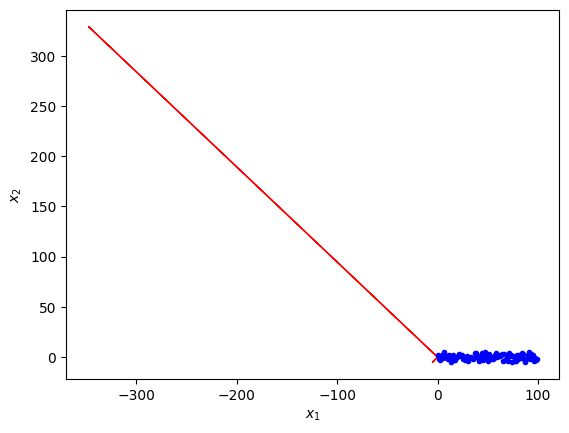

In [ ]:
#variables originales
x1 = np.array([1,0])
x2 = np.array([0,1])

#variables transformadas (componentes principales)
x1t = np.array([v1[0,0],v1[0,1]])
x2t = np.array([v2[0,0],v2[0,1]])

fig = plt.figure()
ax = fig.add_subplot(111)
plt.plot(X[:,0],X[:,1],'b.')
plt.arrow(0,0,7*x1t[0]*l[0]/l[1],7*x1t[1]*l[0]/l[1], width=0.1, color="r")
plt.arrow(0,0,7*x2t[0],7*x2t[1], width=0.1, color="r")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
ax.set_aspect('equal')
plt.show()

La primera componente principal recibe solamente el $3.7\%$ de la información del conjunto original, mientras que la segunda el $96.3\%$.

In [ ]:
l[1]/(l[0]+l[1])

0.01442977275079037

Dado que la mayor cantidad de información se proyecta en la segunda componente principal, podemos olvidarnos de la primera.

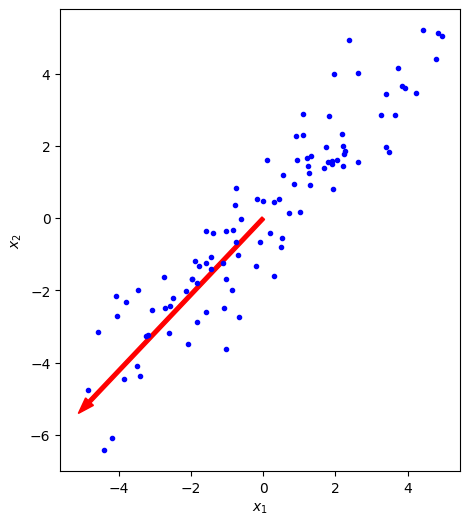

In [ ]:
#variables originales
x1 = np.array([1,0])
x2 = np.array([0,1])


#variables transformadas (componentes principales)
x2t = np.array([v2[0,0],v2[0,1]])

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111)
plt.plot(Xt[:,0],Xt[:,1],'b.')
plt.arrow(0,0,7*x2t[0],7*x2t[1], width=0.1, color="r")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
ax.set_aspect('equal')
plt.show()

Debemos proyectar los datos sobre esta componente para que se representen con una sola dimensión. Eso lo logramos multiplicando:

$$\color{red}{X' = Xv_2^T}$$

Observa que los puntos transformados tienen una dimensión de 1 (se encuentran sobre una recta)

In [ ]:
Xp = np.dot(X[:, :2], np.transpose(v2)) # Select the first two columns of X for the dot product
Xp.shape

(100, 1)

In [ ]:
Xp[:10]

matrix([[-1.42648241],
        [ 0.86512253],
        [ 0.60795529],
        [-2.43547245],
        [-4.34400363],
        [-2.87986895],
        [-7.61642602],
        [-6.15539924],
        [-5.36261273],
        [-5.40540011]])

Visualizamos las proyecciones

IndexError: index 1 is out of bounds for axis 1 with size 1

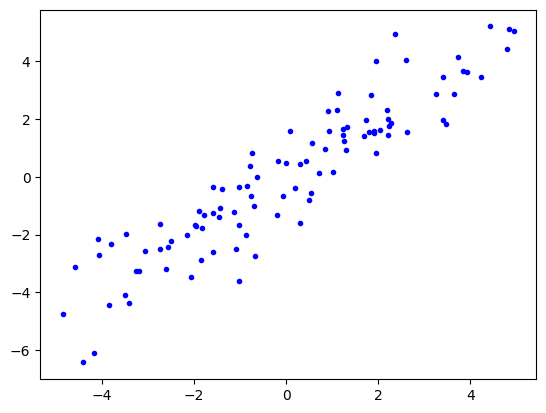

In [ ]:
#variables originales
x1 = np.array([1,0])
x2 = np.array([0,1])

#variables transformadas (componentes principales)
x2t = np.array([v2[0,0],v2[0,1]])

fig = plt.figure()
ax = fig.add_subplot(111)
l = 100
plt.plot(Xt[:l,0],Xt[:l,1],'b.')
plt.plot(Xp[:l,0],Xp[:l,1],'r.')

for i in range(l):
    plt.arrow(Xt[i,0],Xt[i,1],Xp[i,0]-Xt[i,0],Xp[i,1]-Xt[i,1], color="g", alpha=0.25)

plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
ax.set_aspect('equal')
plt.show()

# <font color="red">Actividad </font>

*